# Business Performance Analysis — Sample Superstore
**Python notebook: data cleaning, exploratory analysis, statistics and forecasting**

*Dataset: Sample Superstore — a public sample dataset used for learning. It is NOT confidential data from a real company.*

**Role of Python in the project:** Python is the main analytical tool. In this notebook we (A) inspect the raw data, (B) clean it, (C) engineer analytical variables, (D) run exploratory analysis, (E) apply statistics, (F) test a simple forecast against a baseline, (G) produce charts and (H) export the cleaned file used by SQL and Power BI.

**Contents:** A Inspection · B Cleaning · C Feature engineering · D EDA · E Statistics · F Forecasting · G Findings summary · H Export

In [1]:
import pandas as pd, numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 10})
import os; os.makedirs('../reports/figures', exist_ok=True)
NAVY, TEAL, RED, GREY, GOLD = '#1F3A5F', '#2A9D8F', '#C0392B', '#8A94A0', '#E9A23B'
def save(name): plt.tight_layout(); plt.savefig(f'../reports/figures/{name}.png', dpi=150, bbox_inches='tight')
money = mtick.FuncFormatter(lambda x, p: f'${x/1000:,.0f}K')

## A. Data inspection
**What / why:** Before changing anything we look at the raw file: size, columns, types, missing values and duplicates. Never assume — verify.
Note: `Postal Code` is read as text (`dtype=str`) so we can see whether leading zeros were lost.

In [2]:
raw = pd.read_csv('../data/raw/Sample_Superstore.csv', dtype={'Postal Code': str})
print('Shape (rows, columns):', raw.shape)
raw.head()

Shape (rows, columns): (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


In [3]:
raw.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,Florida,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.25,3,0.20,4.10
9990,9991,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.96,2,0.00,15.63
9991,9992,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.58,2,0.20,19.39
9992,9993,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.60,4,0.00,13.32
9993,9994,CA-2017-119914,5/4/2017,5/9/2017,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,California,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.16,2,0.00,72.95


In [4]:
print(raw.dtypes)
print('\nMissing values per column:'); print(raw.isna().sum()[raw.isna().sum() > 0] if raw.isna().sum().sum() else 'None — 0 missing values in all 21 columns')

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code          str
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

Missing values per column:
None — 0 missing values in all 21 columns


In [5]:
print('Exact duplicate rows (all columns):', raw.duplicated().sum())
cols_wo_id = [c for c in raw.columns if c != 'Row ID']
print('Duplicates ignoring Row ID:', raw.duplicated(subset=cols_wo_id).sum())
raw[raw.duplicated(subset=cols_wo_id, keep=False)].T

Exact duplicate rows (all columns): 0
Duplicates ignoring Row ID: 1


,3405,3406
Row ID,3406,3407
Order ID,US-2014-150119,US-2014-150119
Order Date,4/23/2014,4/23/2014
Ship Date,4/27/2014,4/27/2014
Ship Mode,Standard Class,Standard Class
Customer ID,LB-16795,LB-16795
Customer Name,Laurel Beltran,Laurel Beltran
Segment,Home Office,Home Office
Country,United States,United States
City,Columbus,Columbus


**Reading:** Row ID is unique so there are no exact duplicates, but **one pair of rows is identical in every column except Row ID** (same order, product, quantity, discount). It could be a genuine repeated order line (a customer ordering the same item twice) or a data-entry duplicate. The file gives no way to prove which, so we **keep both rows and flag one** (`Possible Duplicate`). Impact: Sales $281.37 of $2.30M (0.01%) — immaterial.

In [6]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Row ID,"9,994.00","4,997.50","2,885.16",1.00,"2,499.25","4,997.50","7,495.75","9,994.00"
Sales,"9,994.00",229.86,623.25,0.44,17.28,54.49,209.94,"22,638.48"
Quantity,"9,994.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,"9,994.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"9,994.00",28.66,234.26,"-6,599.98",1.73,8.67,29.36,"8,399.98"


In [7]:
# Structure checks: consistency of keys and identifiers
checks = {
 'Customer ID -> >1 name': (raw.groupby('Customer ID')['Customer Name'].nunique() > 1).sum(),
 'Order ID -> >1 customer': (raw.groupby('Order ID')['Customer ID'].nunique() > 1).sum(),
 'Product ID -> >1 product name': (raw.groupby('Product ID')['Product Name'].nunique() > 1).sum(),
 'Product ID -> >1 sub-category': (raw.groupby('Product ID')['Sub-Category'].nunique() > 1).sum(),
 'State -> >1 region': (raw.groupby('State')['Region'].nunique() > 1).sum(),
 'Postal codes with 4 digits': (raw['Postal Code'].str.len() == 4).sum(),
 'Rows with Sales <= 0': (raw['Sales'] <= 0).sum(),
 'Rows with negative Profit': (raw['Profit'] < 0).sum(),
 'Countries': raw['Country'].nunique(),
}
pd.Series(checks, name='count')

Customer ID -> >1 name              0
Order ID -> >1 customer             0
Product ID -> >1 product name      32
Product ID -> >1 sub-category       0
State -> >1 region                  0
Postal codes with 4 digits        438
Rows with Sales <= 0                0
Rows with negative Profit        1871
Countries                           1
Name: count, dtype: int64

**Data-quality issues found**

| # | Issue | Evidence | Decision |
|---|---|---|---|
| 1 | Dates stored as text (`m/d/yyyy`) | dtype = object/str | Convert to datetime |
| 2 | Postal codes lost leading zeros | 438 four-digit codes in 6 states (CT, MA, ME, NH, NJ, RI); Vermont's 11 codes keep their zero, so the source file is itself inconsistent | Pad to 5 digits, store as text |
| 3 | 32 Product IDs carry more than one product name | name variants for same ID | Use most frequent name per ID as canonical; keep original column |
| 4 | One pair of identical rows (except Row ID) | see above | Keep, flag |
| 5 | `Country` is constant | only United States | Keep; no analytical value |
| 6 | No cost column | — | Derive `Cost = Sales − Profit` |
| 7 | Currency/units not stated | — | Assume USD; state as limitation |

## B. Data cleaning
Each step is documented. **No rows are deleted**, so every total in the cleaned file equals the raw file.

In [8]:
df = raw.copy()
# 1) Dates
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date']  = pd.to_datetime(df['Ship Date'],  format='%m/%d/%Y')
# 2) Postal code leading zeros
df['Postal Code'] = df['Postal Code'].str.zfill(5)
# 3) Canonical product name per Product ID (most frequent variant)
canon = df.groupby('Product ID')['Product Name'].agg(lambda s: s.value_counts().index[0])
df['Product Name Original'] = df['Product Name']
df['Product Name'] = df['Product ID'].map(canon)
# 4) Flag the possible duplicate
df['Possible Duplicate'] = df.drop(columns=['Row ID', 'Product Name Original']).duplicated().astype(int)
print('Ship date before order date:', (df['Ship Date'] < df['Order Date']).sum())
print('Postal codes now all 5 digits:', (df['Postal Code'].str.len() == 5).all())
print('Rows changed by product-name standardisation:', (df['Product Name'] != df['Product Name Original']).sum())

Ship date before order date: 0
Postal codes now all 5 digits: True
Rows changed by product-name standardisation: 129


## C. Feature engineering
| Variable | Formula | Business purpose |
|---|---|---|
| Order Year / Quarter / Month | from Order Date | Trend and seasonality |
| Shipping Days | Ship Date − Order Date | Delivery performance |
| Profit Margin | Profit ÷ Sales (blank if Sales = 0) | Profitability independent of order size |
| Cost | Sales − Profit | Implied cost base |
| Is Loss | 1 if Profit < 0 | Loss tracking |
| Discount Band | No discount, 1–10 %, 11–20 %, 21–30 %, 31–50 %, >50 % | Compare discount policies |

In [9]:
df['Order Year']    = df['Order Date'].dt.year
df['Order Quarter'] = df['Order Date'].dt.quarter
df['Order Month']   = df['Order Date'].dt.month
df['Order Month Name'] = df['Order Date'].dt.strftime('%b')
df['Year-Month']    = df['Order Date'].dt.to_period('M').astype(str)
df['Shipping Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Profit Margin'] = np.where(df['Sales'] > 0, df['Profit'] / df['Sales'], np.nan)
df['Cost']          = df['Sales'] - df['Profit']
df['Is Loss']       = (df['Profit'] < 0).astype(int)
bins   = [-0.001, 0, 0.10, 0.20, 0.30, 0.50, 1.0]
labels = ['No discount', '1-10%', '11-20%', '21-30%', '31-50%', '>50%']
df['Discount Band'] = pd.cut(df['Discount'], bins=bins, labels=labels).astype(str)
# Reconciliation: cleaning must not change the totals
assert round(df['Sales'].sum(), 4) == round(raw['Sales'].sum(), 4) and len(df) == len(raw)
print('Reconciliation OK — rows:', len(df), '| Sales:', round(df.Sales.sum(), 2), '| Profit:', round(df.Profit.sum(), 2))
df[['Order Date','Shipping Days','Profit Margin','Cost','Discount','Discount Band']].head()

Reconciliation OK — rows: 9994 | Sales: 2297200.86 | Profit: 286397.02


,Order Date,Shipping Days,Profit Margin,Cost,Discount,Discount Band
0,2016-11-08,3,0.16,220.05,0.00,No discount
1,2016-11-08,3,0.30,512.36,0.00,No discount
2,2016-06-12,4,0.47,7.75,0.00,No discount
3,2015-10-11,7,-0.40,"1,340.61",0.45,31-50%
4,2015-10-11,7,0.11,19.85,0.20,11-20%


## D. Exploratory data analysis
A helper function builds the same KPI table for any grouping so that every comparison uses identical definitions:
**Profit Margin = Profit ÷ Sales** (computed on group totals, not the average of row margins) and **Orders = distinct Order IDs**.

In [10]:
def kpi(by, data=df):
    t = data.groupby(by).agg(Sales=('Sales','sum'), Profit=('Profit','sum'),
                             Orders=('Order ID','nunique'), Quantity=('Quantity','sum'),
                             Avg_Discount=('Discount','mean'))
    t['Margin %'] = t['Profit'] / t['Sales'] * 100
    t['Sales share %'] = t['Sales'] / data['Sales'].sum() * 100
    return t

total_sales, total_profit = df.Sales.sum(), df.Profit.sum()
n_orders, n_cust = df['Order ID'].nunique(), df['Customer ID'].nunique()
summary = pd.Series({
 'Total Sales': total_sales, 'Total Profit': total_profit, 'Profit Margin %': total_profit/total_sales*100,
 'Distinct Orders': n_orders, 'Distinct Customers': n_cust, 'Total Quantity': df.Quantity.sum(),
 'Average Order Value': total_sales/n_orders, 'Average Discount % (row level)': df.Discount.mean()*100,
 'Average Shipping Days': df['Shipping Days'].mean(), 'Loss-making lines': df['Is Loss'].sum(),
 'Loss-making lines %': df['Is Loss'].mean()*100, 'Total losses on those lines': df.loc[df.Profit<0,'Profit'].sum()})
summary

Total Sales                      2,297,200.86
Total Profit                       286,397.02
Profit Margin %                         12.47
Distinct Orders                      5,009.00
Distinct Customers                     793.00
Total Quantity                      37,873.00
Average Order Value                    458.61
Average Discount % (row level)          15.62
Average Shipping Days                    3.96
Loss-making lines                    1,871.00
Loss-making lines %                     18.72
Total losses on those lines       -156,131.29
dtype: float64

### D1. Time trends

In [11]:
yearly = kpi('Order Year'); yearly['Sales growth %'] = yearly['Sales'].pct_change()*100; yearly['Profit growth %'] = yearly['Profit'].pct_change()*100
yearly

,Sales,Profit,Orders,Quantity,Avg_Discount,Margin %,Sales share %,Sales growth %,Profit growth %
Order Year,,,,,,,,,
2014,"484,247.50","49,543.97",969,7581,0.16,10.23,21.08,NaN,NaN
2015,"470,532.51","61,618.60",1038,7979,0.16,13.10,20.48,-2.83,24.37
2016,"609,205.60","81,795.17",1315,9837,0.15,13.43,26.52,29.47,32.74
2017,"733,215.26","93,439.27",1687,12476,0.16,12.74,31.92,20.36,14.24


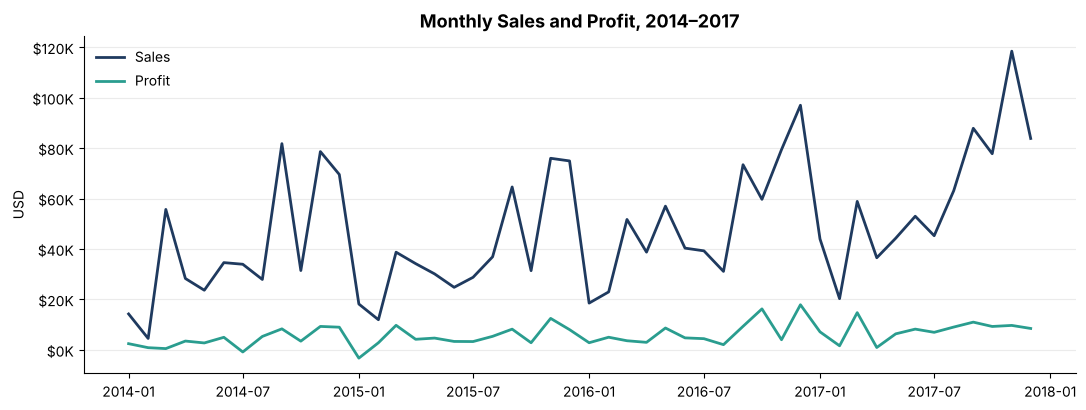

In [12]:
monthly = df.groupby('Year-Month').agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
monthly.index = pd.to_datetime(monthly.index)
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(monthly.index, monthly.Sales, color=NAVY, lw=2, label='Sales')
ax.plot(monthly.index, monthly.Profit, color=TEAL, lw=2, label='Profit')
ax.yaxis.set_major_formatter(money); ax.set_title('Monthly Sales and Profit, 2014–2017'); ax.set_ylabel('USD'); ax.legend(frameon=False)
ax.grid(axis='y', alpha=.25); save('01_monthly_sales_profit'); plt.show()

**Interpretation:** Sales are strongly seasonal — peaks every September–December and troughs in January–February — with an upward trend from 2016. Profit follows the same shape but is far more volatile and is a small fraction of sales.

         Sales    Profit  Share of sales %
Jan  94,924.84  9,134.45              4.13
Feb  59,751.25 10,294.61              2.60
Mar 205,005.49 28,594.69              8.92
Apr 137,762.13 11,587.44              6.00
May 155,028.81 22,411.31              6.75
Jun 152,718.68 21,285.80              6.65
Jul 147,238.10 13,832.66              6.41
Aug 159,044.06 21,776.94              6.92
Sep 307,649.95 36,857.48             13.39
Oct 200,322.98 31,784.04              8.72
Nov 352,461.07 35,468.43             15.34
Dec 325,293.50 43,369.19             14.16


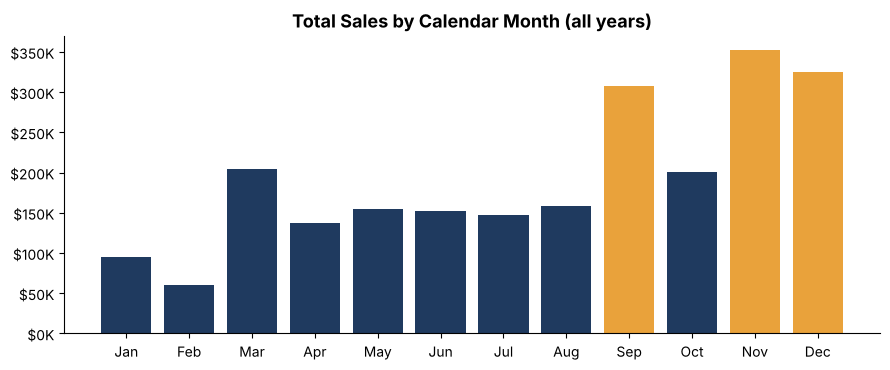

In [13]:
season = df.groupby('Order Month')[['Sales','Profit']].sum()
season['Share of sales %'] = season.Sales/season.Sales.sum()*100
season.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
print(season.round(2))
fig, ax = plt.subplots(figsize=(9, 3.8)); ax.bar(season.index, season.Sales, color=[GOLD if m in ('Sep','Nov','Dec') else NAVY for m in season.index])
ax.yaxis.set_major_formatter(money); ax.set_title('Total Sales by Calendar Month (all years)'); save('02_seasonality'); plt.show()

### D2. Category and sub-category performance

In [14]:
cat = kpi('Category').sort_values('Sales', ascending=False); cat

,Sales,Profit,Orders,Quantity,Avg_Discount,Margin %,Sales share %
Category,,,,,,,
Technology,"836,154.03","145,454.95",1544,6939,0.13,17.40,36.40
Furniture,"741,999.80","18,451.27",1764,8028,0.17,2.49,32.30
Office Supplies,"719,047.03","122,490.80",3742,22906,0.16,17.04,31.30


In [15]:
sub = kpi('Sub-Category').sort_values('Profit'); sub

,Sales,Profit,Orders,Quantity,Avg_Discount,Margin %,Sales share %
Sub-Category,,,,,,,
Tables,"206,965.53","-17,725.48",307,1241,0.26,-8.56,9.01
Bookcases,"114,880.00","-3,472.56",224,868,0.21,-3.02,5.00
Supplies,"46,673.54","-1,189.10",187,647,0.08,-2.55,2.03
Fasteners,"3,024.28",949.52,215,914,0.08,31.40,0.13
Machines,"189,238.63","3,384.76",112,440,0.31,1.79,8.24
Labels,"12,486.31","5,546.25",346,1400,0.07,44.42,0.54
Art,"27,118.79","6,527.79",731,3000,0.07,24.07,1.18
Envelopes,"16,476.40","6,964.18",249,906,0.08,42.27,0.72
Furnishings,"91,705.16","13,059.14",877,3563,0.14,14.24,3.99


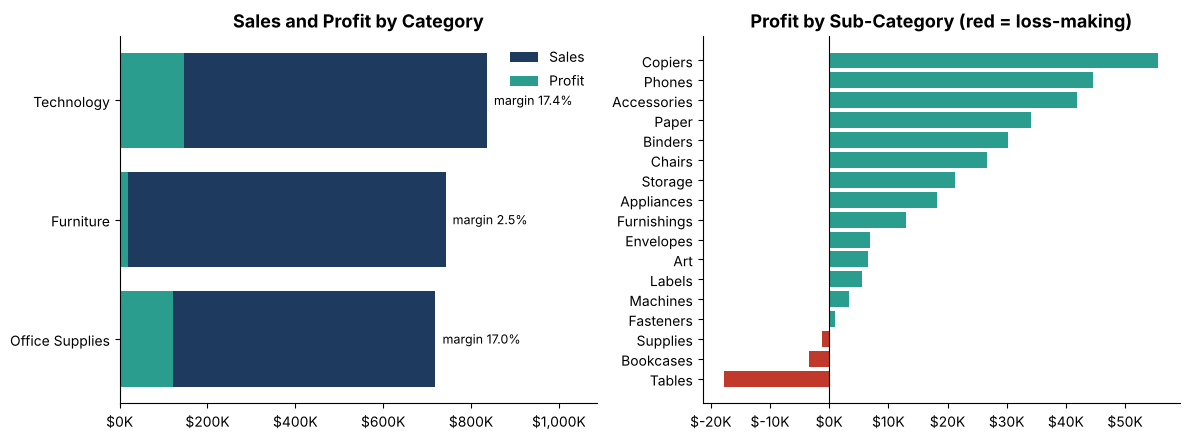

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
c = kpi('Category').sort_values('Sales')
axes[0].barh(c.index, c.Sales, color=NAVY, label='Sales'); axes[0].barh(c.index, c.Profit, color=TEAL, label='Profit')
axes[0].xaxis.set_major_formatter(money); axes[0].set_title('Sales and Profit by Category'); axes[0].legend(frameon=False)
for i, (s, m) in enumerate(zip(c.Sales, c['Margin %'])): axes[0].text(s, i, f'  margin {m:.1f}%', va='center', fontsize=9)
axes[0].set_xlim(0, c.Sales.max()*1.3)
s = sub
axes[1].barh(s.index, s.Profit, color=[RED if v < 0 else TEAL for v in s.Profit]); axes[1].xaxis.set_major_formatter(money)
axes[1].set_title('Profit by Sub-Category (red = loss-making)'); axes[1].axvline(0, color='k', lw=.8)
save('03_category_subcategory'); plt.show()

**Interpretation:** Technology and Office Supplies earn ~17 % margins. Note that Binders, although profitable overall (14.9 % margin), carries $38.5K of line-level losses — all in the >50 % discount band. Furniture has similar sales to Office Supplies but earns only ~2.5 % margin. Three sub-categories lose money overall: **Tables, Bookcases, Supplies**. Machines are almost break-even despite $189K of sales.

### D3. Best- and worst-performing products

In [17]:
prod = kpi(['Product ID', 'Product Name'])   # Product ID is the true product key (1,862 IDs; 1,818 distinct names)
print('Top 10 by profit'); display(prod.sort_values('Profit', ascending=False).head(10)[['Sales','Profit','Margin %','Avg_Discount']])
print('Bottom 10 by profit'); display(prod.sort_values('Profit').head(10)[['Sales','Profit','Margin %','Avg_Discount']])
# round to cents so floating-point noise (e.g. -3.6e-15) is not mistaken for a loss
neg = prod.Profit.round(2) < 0
print('Products (by Product ID) with negative total profit:', neg.sum(), 'of', len(prod), f'({neg.mean()*100:.1f}%)')
print('Total profit lost on those products: $', round(prod.loc[neg,'Profit'].sum(), 2))

Top 10 by profit


,,Sales,Profit,Margin %,Avg_Discount
Product ID,Product Name,,,,
TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,"61,599.82","25,199.93",40.91,0.12
OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,"27,453.38","7,753.04",28.24,0.24
TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,"18,839.69","6,983.88",37.07,0.20
TEC-CO-10003763,Canon PC1060 Personal Laser Copier,"11,619.83","4,570.93",39.34,0.15
TEC-AC-10002049,Logitech G19 Programmable Gaming Keyboard,"13,756.54","4,425.34",32.17,0.04
TEC-MA-10001127,"HP Designjet T520 Inkjet Large Format Printer - 24"" Color","18,374.90","4,094.98",22.29,0.17
TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,"7,699.89","3,772.95",49.00,0.00
TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta","14,299.89","3,717.97",26.00,0.00
OFF-BI-10001120,Ibico EPK-21 Electric Binding System,"15,875.92","3,345.28",21.07,0.33


Bottom 10 by profit


,,Sales,Profit,Margin %,Avg_Discount
Product ID,Product Name,,,,
TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,"11,099.96","-8,879.97",-80.00,0.53
TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,"16,829.90","-4,589.97",-27.27,0.40
TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,"7,999.98","-3,839.99",-48.00,0.50
FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,"9,917.64","-2,876.12",-29.00,0.28
FUR-TA-10001889,Bush Advantage Collection Racetrack Conference Table,"9,544.73","-1,934.40",-20.27,0.35
OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,"17,965.07","-1,878.17",-10.45,0.45
TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48","-1,811.08",-8.00,0.50
OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Opener,"16,656.20","-1,299.18",-7.80,0.10
FUR-TA-10001950,Balt Solid Wood Round Tables,"6,518.75","-1,201.06",-18.42,0.20


Products (by Product ID) with negative total profit: 299 of 1862 (16.1%)
Total profit lost on those products: $ -76721.13


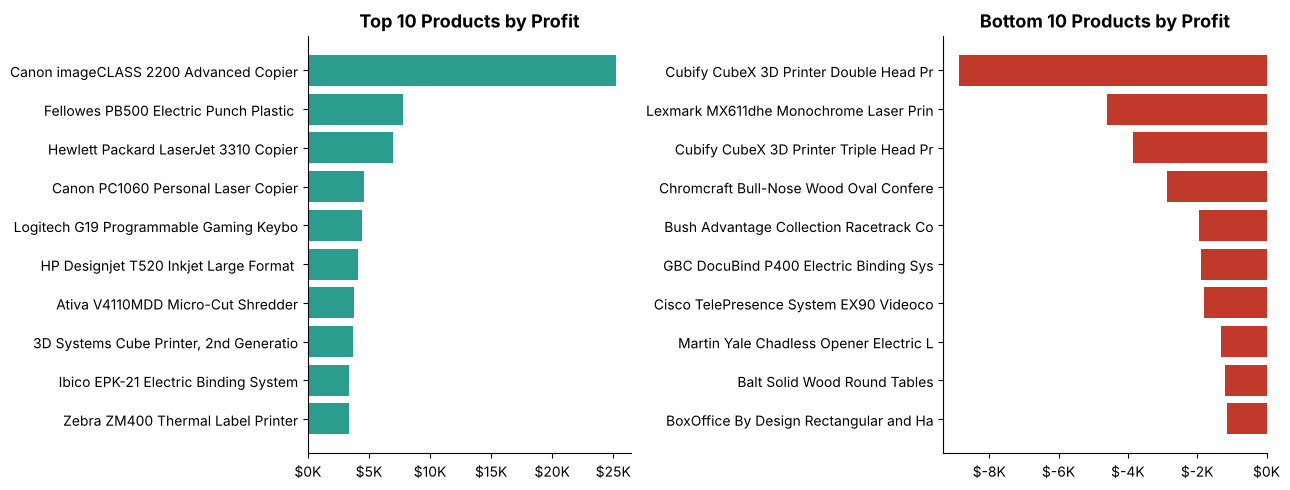

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
t = prod.sort_values('Profit', ascending=False).head(10)[::-1]; b = prod.sort_values('Profit').head(10)[::-1]
axes[0].barh([n[1][:38] for n in t.index], t.Profit, color=TEAL); axes[0].set_title('Top 10 Products by Profit'); axes[0].xaxis.set_major_formatter(money)
axes[1].barh([n[1][:38] for n in b.index], b.Profit, color=RED); axes[1].set_title('Bottom 10 Products by Profit'); axes[1].xaxis.set_major_formatter(money)
save('04_top_bottom_products'); plt.show()

### D4. Regional and geographic performance

In [19]:
reg = kpi('Region').sort_values('Profit', ascending=False); reg

,Sales,Profit,Orders,Quantity,Avg_Discount,Margin %,Sales share %
Region,,,,,,,
West,"725,457.82","108,418.45",1611,12266,0.11,14.94,31.58
East,"678,781.24","91,522.78",1401,10618,0.15,13.48,29.55
South,"391,721.91","46,749.43",822,6209,0.15,11.93,17.05
Central,"501,239.89","39,706.36",1175,8780,0.24,7.92,21.82


In [20]:
state = kpi('State').sort_values('Profit')
print('Loss-making states:', (state.Profit < 0).sum()); display(state[state.Profit < 0][['Sales','Profit','Margin %','Avg_Discount']])
print('Top 5 states by profit'); display(state.tail(5)[['Sales','Profit','Margin %','Avg_Discount']])
city = kpi('City').sort_values('Profit'); print('Worst 5 cities'); display(city.head(5)[['Sales','Profit','Margin %']])

Loss-making states: 10


,Sales,Profit,Margin %,Avg_Discount
State,,,,
Texas,"170,188.05","-25,729.36",-15.12,0.37
Ohio,"78,258.14","-16,971.38",-21.69,0.32
Pennsylvania,"116,511.91","-15,559.96",-13.35,0.33
Illinois,"80,166.10","-12,607.89",-15.73,0.39
North Carolina,"55,603.16","-7,490.91",-13.47,0.28
Colorado,"32,108.12","-6,527.86",-20.33,0.32
Tennessee,"30,661.87","-5,341.69",-17.42,0.29
Arizona,"35,282.00","-3,427.92",-9.72,0.30
Florida,"89,473.71","-3,399.30",-3.80,0.30


Top 5 states by profit


,Sales,Profit,Margin %,Avg_Discount
State,,,,
Virginia,"70,636.72","18,597.95",26.33,0.00
Michigan,"76,269.61","24,463.19",32.07,0.01
Washington,"138,641.27","33,402.65",24.09,0.06
New York,"310,876.27","74,038.55",23.82,0.06
California,"457,687.63","76,381.39",16.69,0.07


Worst 5 cities


,Sales,Profit,Margin %
City,,,
Philadelphia,"109,077.01","-13,837.77",-12.69
Houston,"64,504.76","-10,153.55",-15.74
San Antonio,"21,843.53","-7,299.05",-33.42
Lancaster,"9,891.46","-7,239.07",-73.19
Chicago,"48,539.54","-6,654.57",-13.71


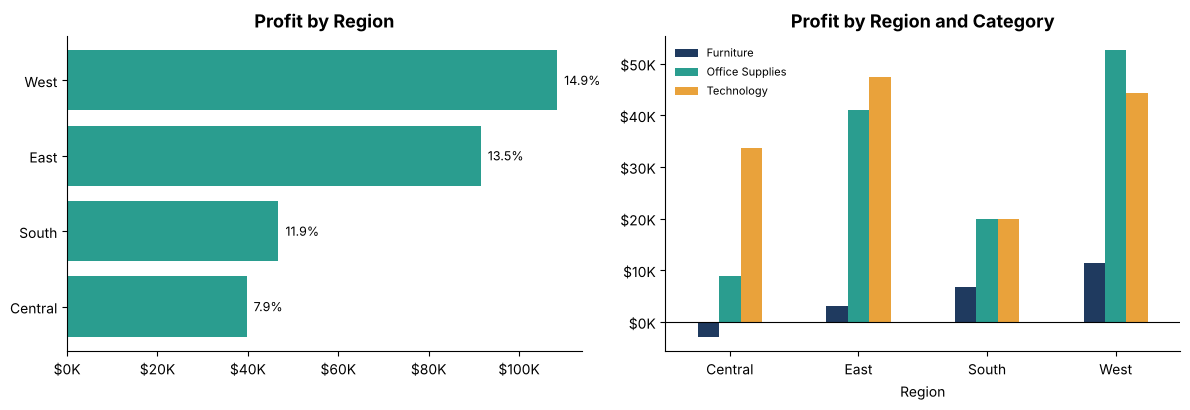

Category,Furniture,Office Supplies,Technology
Region,,,
Central,"-2,871.00","8,880.00","33,697.00"
East,"3,046.00","41,015.00","47,462.00"
South,"6,771.00","19,986.00","19,992.00"
West,"11,505.00","52,610.00","44,304.00"


In [21]:
rc = df.pivot_table(index='Region', columns='Category', values='Profit', aggfunc='sum')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
r = kpi('Region').sort_values('Profit'); axes[0].barh(r.index, r.Profit, color=TEAL); axes[0].xaxis.set_major_formatter(money); axes[0].set_title('Profit by Region')
for i, (p, m) in enumerate(zip(r.Profit, r['Margin %'])): axes[0].text(p, i, f'  {m:.1f}%', va='center', fontsize=9)
rc.plot(kind='bar', ax=axes[1], color=[NAVY, TEAL, GOLD], rot=0); axes[1].yaxis.set_major_formatter(money); axes[1].set_title('Profit by Region and Category'); axes[1].legend(frameon=False, fontsize=8); axes[1].axhline(0, color='k', lw=.8)
save('05_region_profit'); plt.show()
rc.round(0)

**Interpretation:** West is the largest and most profitable region. **Central** has the second-lowest sales but the lowest margin (7.9 %) and the highest average discount (24 %); Central Furniture loses money. Texas, Ohio, Pennsylvania and Illinois each lose $12–26K.

### D5. Customer segments and purchasing behaviour

In [22]:
seg = kpi('Segment').sort_values('Sales', ascending=False)
seg['Avg order value'] = seg.Sales / seg.Orders
cust_cnt = df.groupby('Segment')['Customer ID'].nunique(); seg['Customers'] = cust_cnt; seg['Sales per customer'] = seg.Sales/seg.Customers
seg

,Sales,Profit,Orders,Quantity,Avg_Discount,Margin %,Sales share %,Avg order value,Customers,Sales per customer
Segment,,,,,,,,,,
Consumer,"1,161,401.34","134,119.21",2586,19521,0.16,11.55,50.56,449.11,409,"2,839.61"
Corporate,"706,146.37","91,979.13",1514,11608,0.16,13.03,30.74,466.41,236,"2,992.15"
Home Office,"429,653.15","60,298.68",909,6744,0.15,14.03,18.70,472.67,148,"2,903.06"


In [23]:
cust = df.groupby('Customer ID').agg(Name=('Customer Name','first'), Sales=('Sales','sum'), Profit=('Profit','sum'), Orders=('Order ID','nunique')).sort_values('Sales', ascending=False)
cust['Cum share %'] = cust.Sales.cumsum()/cust.Sales.sum()*100
print('Top 10 customers by sales'); display(cust.head(10))
top20 = int(len(cust)*0.2); print(f'Top 20% of customers ({top20}) generate {cust.Sales.head(top20).sum()/cust.Sales.sum()*100:.1f}% of sales')
print('Customers with negative total profit:', (cust.Profit<0).sum(), 'of', len(cust))
orders = df.groupby('Order ID').agg(Sales=('Sales','sum'), Lines=('Row ID','count'), Date=('Order Date','first'), Cust=('Customer ID','first'))
print('\nOrder value: mean %.2f | median %.2f' % (orders.Sales.mean(), orders.Sales.median()))
oc = orders.groupby('Cust').size(); print('Orders per customer: mean %.1f, min %d, max %d' % (oc.mean(), oc.min(), oc.max()))
print('Repeat customers (>1 order): %.1f%%' % ((oc>1).mean()*100))

Top 10 customers by sales


,Name,Sales,Profit,Orders,Cum share %
Customer ID,,,,,
SM-20320,Sean Miller,"25,043.05","-1,980.74",5,1.09
TC-20980,Tamara Chand,"19,052.22","8,981.32",5,1.92
RB-19360,Raymond Buch,"15,117.34","6,976.10",6,2.58
TA-21385,Tom Ashbrook,"14,595.62","4,703.79",4,3.21
AB-10105,Adrian Barton,"14,473.57","5,444.81",10,3.84
KL-16645,Ken Lonsdale,"14,175.23",806.86,12,4.46
SC-20095,Sanjit Chand,"14,142.33","5,757.41",9,5.08
HL-15040,Hunter Lopez,"12,873.30","5,622.43",6,5.64
SE-20110,Sanjit Engle,"12,209.44","2,650.68",11,6.17


Top 20% of customers (158) generate 48.0% of sales
Customers with negative total profit: 155 of 793

Order value: mean 458.61 | median 151.96
Orders per customer: mean 6.3, min 1, max 17
Repeat customers (>1 order): 98.5%


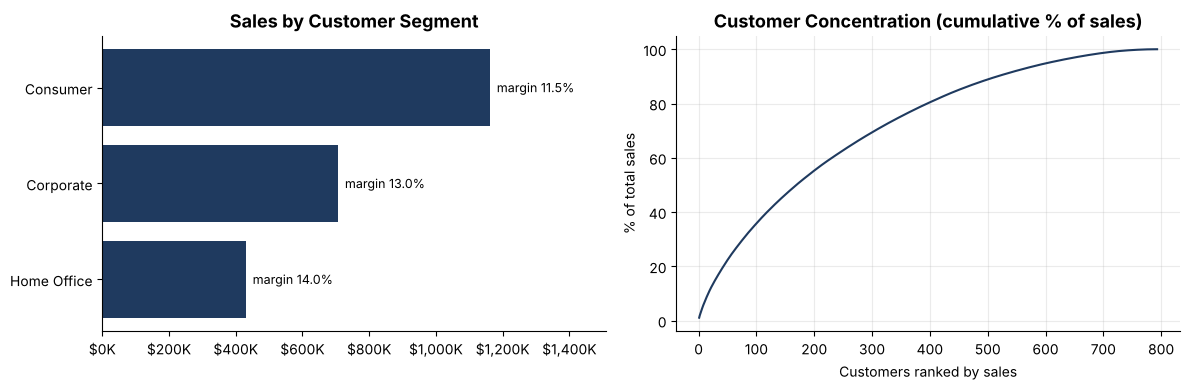

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
s = kpi('Segment').sort_values('Sales'); axes[0].barh(s.index, s.Sales, color=NAVY); axes[0].xaxis.set_major_formatter(money); axes[0].set_title('Sales by Customer Segment')
for i, (v, m) in enumerate(zip(s.Sales, s['Margin %'])): axes[0].text(v, i, f'  margin {m:.1f}%', va='center', fontsize=9)
axes[0].set_xlim(0, s.Sales.max()*1.3)
axes[1].plot(range(1, len(cust)+1), cust['Cum share %'], color=NAVY); axes[1].set_title('Customer Concentration (cumulative % of sales)')
axes[1].set_xlabel('Customers ranked by sales'); axes[1].set_ylabel('% of total sales'); axes[1].grid(alpha=.25)
save('06_segments_customers'); plt.show()

### D6. Discounts and profitability

In [25]:
disc = kpi('Discount Band').reindex(['No discount','1-10%','11-20%','21-30%','31-50%','>50%'])
disc['Avg profit per line'] = df.groupby('Discount Band').Profit.mean()
disc['% lines loss-making'] = df.groupby('Discount Band')['Is Loss'].mean()*100
disc

,Sales,Profit,Orders,Quantity,Avg_Discount,Margin %,Sales share %,Avg profit per line,% lines loss-making
Discount Band,,,,,,,,,
No discount,"1,087,908.47","320,987.60",2644,18267,0.00,29.51,47.36,66.90,0.00
1-10%,"54,369.35","9,029.18",89,373,0.10,16.61,2.37,96.06,4.26
11-20%,"792,152.89","91,756.30",2436,13858,0.20,11.58,34.48,24.74,13.99
21-30%,"103,226.65","-10,369.28",211,849,0.30,-10.05,4.49,-45.68,91.63
31-50%,"195,314.76","-48,447.73",280,1177,0.42,-24.80,8.50,-156.28,91.61
>50%,"64,228.74","-76,559.05",685,3349,0.72,-119.20,2.80,-89.44,100.00


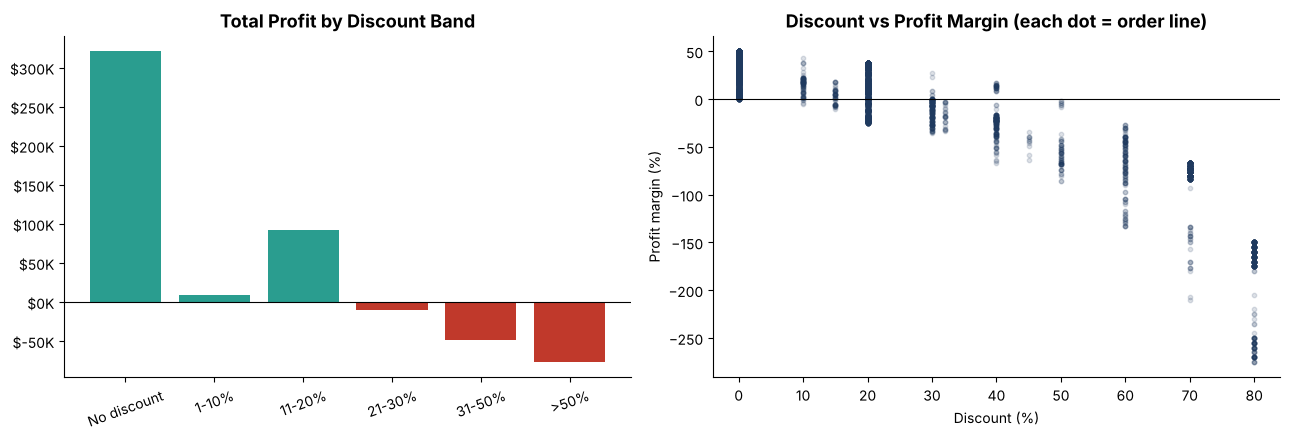

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(disc.index, disc.Profit, color=[RED if v < 0 else TEAL for v in disc.Profit]); axes[0].yaxis.set_major_formatter(money)
axes[0].set_title('Total Profit by Discount Band'); axes[0].axhline(0, color='k', lw=.8); axes[0].tick_params(axis='x', rotation=20)
axes[1].scatter(df.Discount*100, df['Profit Margin']*100, alpha=.15, s=10, color=NAVY)
axes[1].set_xlabel('Discount (%)'); axes[1].set_ylabel('Profit margin (%)'); axes[1].set_title('Discount vs Profit Margin (each dot = order line)'); axes[1].axhline(0, color='k', lw=.8)
save('07_discount_profit'); plt.show()

In [27]:
# Where does the loss start? Share of lines that are loss-making by exact discount level
lv = df.groupby('Discount').agg(Lines=('Row ID','count'), Profit=('Profit','sum'), Loss_share=('Is Loss','mean'))
lv['Loss_share'] *= 100; lv

,Lines,Profit,Loss_share
Discount,,,
0.00,4798,"320,987.60",0.00
0.10,94,"9,029.18",4.26
0.15,52,"1,418.99",32.69
0.20,3657,"90,337.31",13.73
0.30,227,"-10,369.28",91.63
0.32,27,"-2,391.14",100.00
0.40,206,"-23,057.05",87.38
0.45,11,"-2,493.11",100.00
0.50,66,"-20,506.43",100.00


In [28]:
high_disc = df[df.Discount > 0.20]
print(f'Lines with discount > 20%: {len(high_disc):,} ({len(high_disc)/len(df)*100:.1f}% of lines) | Sales ${high_disc.Sales.sum():,.0f} ({high_disc.Sales.sum()/df.Sales.sum()*100:.1f}% of sales) | Profit ${high_disc.Profit.sum():,.0f}')
print(f'Profit on all other lines: ${df[df.Discount<=0.20].Profit.sum():,.0f}')
print(f'Total profit would be ${df[df.Discount<=0.20].Profit.sum():,.0f} vs actual ${df.Profit.sum():,.0f} if no line had a discount above 20% (illustrative arithmetic only; assumes the same sales volume).')

Lines with discount > 20%: 1,393 (13.9% of lines) | Sales $362,770 (15.8% of sales) | Profit $-135,376
Profit on all other lines: $421,773
Total profit would be $421,773 vs actual $286,397 if no line had a discount above 20% (illustrative arithmetic only; assumes the same sales volume).


**Interpretation:** The pattern is stark. Lines with no discount earn a 29.5 % margin; at 11–20 % margin falls to 11.6 %; every band above 20 % loses money in total, and discounts above 50 % lose $1.19 for every $1 of sales. Every line discounted 45 % or more is loss-making, and so are 91.6 % of lines at 30 %. **Caution:** this is association, not proven causation — heavily discounted products may also be lower-margin products or clearance items. The dataset has no cost list or price history, so we cannot separate the two explanations.

### D7. Shipping performance

In [29]:
ship = df.groupby('Ship Mode').agg(Lines=('Row ID','count'), Avg_days=('Shipping Days','mean'), Min=('Shipping Days','min'), Max=('Shipping Days','max'), Sales=('Sales','sum'), Profit=('Profit','sum'))
ship['Margin %'] = ship.Profit/ship.Sales*100; ship['Share of lines %'] = ship.Lines/len(df)*100; ship

,Lines,Avg_days,Min,Max,Sales,Profit,Margin %,Share of lines %
Ship Mode,,,,,,,,
First Class,1538,2.18,1,4,"351,428.42","48,969.84",13.93,15.39
Same Day,543,0.04,0,1,"128,363.12","15,891.76",12.38,5.43
Second Class,1945,3.24,1,5,"459,193.57","57,446.64",12.51,19.46
Standard Class,5968,5.01,3,7,"1,358,215.74","164,088.79",12.08,59.72


Overall average shipping days: 3.96
{2014: 4.0, 2015: 4.01, 2016: 3.95, 2017: 3.91}
{'Central': 4.06, 'East': 3.91, 'South': 3.96, 'West': 3.93}
Correlation shipping days vs profit margin: -0.012


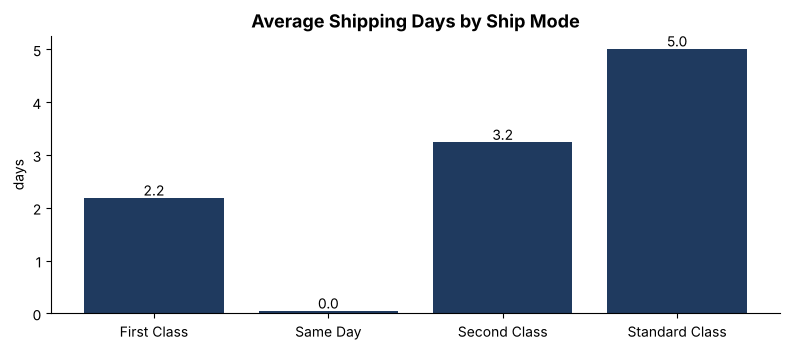

In [30]:
print('Overall average shipping days: %.2f' % df['Shipping Days'].mean())
yr = df.groupby('Order Year')['Shipping Days'].mean(); print(yr.round(2).to_dict())
rg = df.groupby('Region')['Shipping Days'].mean(); print(rg.round(2).to_dict())
print('Correlation shipping days vs profit margin: %.3f' % df[['Shipping Days','Profit Margin']].corr().iloc[0,1])
fig, ax = plt.subplots(figsize=(8, 3.6)); ax.bar(ship.index, ship.Avg_days, color=NAVY); ax.set_title('Average Shipping Days by Ship Mode'); ax.set_ylabel('days')
for i, v in enumerate(ship.Avg_days): ax.text(i, v+.05, f'{v:.1f}', ha='center')
save('08_shipping'); plt.show()

**Interpretation:** Ship modes behave as labelled (Same Day ≈ 0 days, First Class ≈ 2, Second Class ≈ 3.2, Standard ≈ 5). Profit margin is virtually unrelated to shipping speed (correlation ≈ −0.01), so shipping is not a driver of profitability in this data. Delivery *cost* is not recorded, so shipping profitability cannot be assessed.

### D8. Unusual observations and loss-making transactions

In [31]:
loss = df[df.Profit < 0]
print(f'Loss-making lines: {len(loss):,} ({len(loss)/len(df)*100:.1f}%) | total loss ${loss.Profit.sum():,.0f} | equals {abs(loss.Profit.sum())/df[df.Profit>0].Profit.sum()*100:.1f}% of all profit earned on profitable lines')
print('\nLoss by sub-category (lines with Profit<0 only):'); display(loss.groupby('Sub-Category').agg(Lines=('Row ID','count'), Loss=('Profit','sum')).sort_values('Loss').head(6))
print('Ten largest single-line losses:'); display(loss.nsmallest(10, 'Profit')[['Order ID','Product Name','Region','Sales','Discount','Profit']])

Loss-making lines: 1,871 (18.7%) | total loss $-156,131 | equals 35.3% of all profit earned on profitable lines

Loss by sub-category (lines with Profit<0 only):


,Lines,Loss
Sub-Category,,
Binders,613,"-38,510.50"
Tables,203,"-32,412.15"
Machines,44,"-30,118.67"
Bookcases,109,"-12,152.21"
Chairs,235,"-9,880.84"
Appliances,67,"-8,629.64"


Ten largest single-line losses:


,Order ID,Product Name,Region,Sales,Discount,Profit
7772,CA-2016-108196,Cubify CubeX 3D Printer Double Head Print,East,"4,499.98",0.70,"-6,599.98"
683,US-2017-168116,Cubify CubeX 3D Printer Triple Head Print,South,"7,999.98",0.50,"-3,839.99"
9774,CA-2014-169019,GBC DocuBind P400 Electric Binding System,Central,"2,177.58",0.80,"-3,701.89"
3011,CA-2017-134845,Lexmark MX611dhe Monochrome Laser Printer,West,"2,549.99",0.70,"-3,399.98"
4991,US-2017-122714,Ibico EPK-21 Electric Binding System,Central,"1,889.99",0.80,"-2,929.48"
3151,CA-2015-147830,Cubify CubeX 3D Printer Double Head Print,East,"1,799.99",0.70,"-2,639.99"
5310,CA-2017-131254,Fellowes PB500 Electric Punch Plastic Comb Bin...,Central,"1,525.19",0.80,"-2,287.78"
9639,CA-2015-116638,Chromcraft Bull-Nose Wood Oval Conference Tabl...,South,"4,297.64",0.40,"-1,862.31"
1199,CA-2016-130946,GBC DocuBind P400 Electric Binding System,Central,"1,088.79",0.80,"-1,850.95"
2697,CA-2014-145317,Cisco TelePresence System EX90 Videoconferenci...,South,"22,638.48",0.50,"-1,811.08"


Sales    : 1,167 outliers (11.7%)  fences [-271.7, 498.9]
Profit   : 1,881 outliers (18.8%)  fences [-39.7, 70.8]
Quantity :   170 outliers ( 1.7%)  fences [-2.5, 9.5]

Top 5 sales lines:


,Order ID,Product Name,Sales,Discount,Profit
2697,CA-2014-145317,Cisco TelePresence System EX90 Videoconferenci...,"22,638.48",0.50,"-1,811.08"
6826,CA-2016-118689,Canon imageCLASS 2200 Advanced Copier,"17,499.95",0.00,"8,399.98"
8153,CA-2017-140151,Canon imageCLASS 2200 Advanced Copier,"13,999.96",0.00,"6,719.98"
2623,CA-2017-127180,Canon imageCLASS 2200 Advanced Copier,"11,199.97",0.20,"3,919.99"
4190,CA-2017-166709,Canon imageCLASS 2200 Advanced Copier,"10,499.97",0.00,"5,039.99"


Top 5 profit lines:


,Order ID,Product Name,Sales,Discount,Profit
6826,CA-2016-118689,Canon imageCLASS 2200 Advanced Copier,"17,499.95",0.00,"8,399.98"
8153,CA-2017-140151,Canon imageCLASS 2200 Advanced Copier,"13,999.96",0.00,"6,719.98"
4190,CA-2017-166709,Canon imageCLASS 2200 Advanced Copier,"10,499.97",0.00,"5,039.99"
9039,CA-2016-117121,GBC Ibimaster 500 Manual ProClick Binding System,"9,892.74",0.00,"4,946.37"
4098,CA-2014-116904,Ibico EPK-21 Electric Binding System,"9,449.95",0.00,"4,630.48"


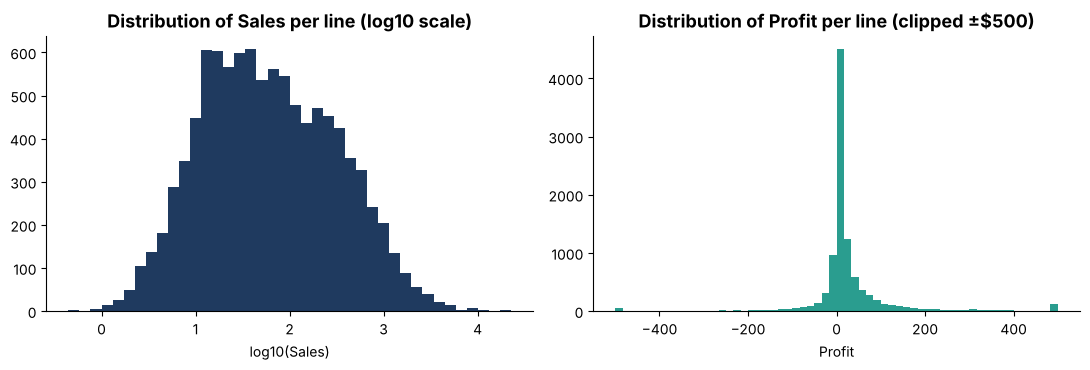

In [32]:
# Outliers using the IQR rule (Tukey fences) on Sales and Profit
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; lo, hi = q1 - 1.5*i, q3 + 1.5*i
    return ((s < lo) | (s > hi)).sum(), lo, hi
for col in ['Sales', 'Profit', 'Quantity']:
    n, lo, hi = iqr_outliers(df[col]); print(f'{col:9s}: {n:5,} outliers ({n/len(df)*100:4.1f}%)  fences [{lo:,.1f}, {hi:,.1f}]')
print('\nTop 5 sales lines:'); display(df.nlargest(5, 'Sales')[['Order ID','Product Name','Sales','Discount','Profit']])
print('Top 5 profit lines:'); display(df.nlargest(5, 'Profit')[['Order ID','Product Name','Sales','Discount','Profit']])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(np.log10(df.Sales), bins=40, color=NAVY); axes[0].set_title('Distribution of Sales per line (log10 scale)'); axes[0].set_xlabel('log10(Sales)')
axes[1].hist(df.Profit.clip(-500, 500), bins=60, color=TEAL); axes[1].set_title('Distribution of Profit per line (clipped ±$500)'); axes[1].set_xlabel('Profit')
save('09_distributions'); plt.show()

**Interpretation:** Sales and profit are heavily right-skewed: most lines are small, a handful are very large (the biggest sale is a $22.6K video-conferencing system; the biggest profit is $8.4K on a copier). Because of this skew the **median is more representative than the mean** for a typical line. IQR outliers are *real* high-value orders, not errors, so they are kept; they matter because a few large lines move totals a lot.

## E. Statistical analysis

In [33]:
desc = df[['Sales','Quantity','Discount','Profit','Shipping Days']].agg(['mean','median','std','min','max','skew']).T
desc['CV (std/mean)'] = desc['std']/desc['mean']; desc

,mean,median,std,min,max,skew,CV (std/mean)
Sales,229.86,54.49,623.25,0.44,"22,638.48",12.97,2.71
Quantity,3.79,3.00,2.23,1.00,14.00,1.28,0.59
Discount,0.16,0.20,0.21,0.00,0.80,1.68,1.32
Profit,28.66,8.67,234.26,"-6,599.98","8,399.98",7.56,8.17
Shipping Days,3.96,4.00,1.75,0.00,7.00,-0.42,0.44


**Reading:** For Sales the mean ($229.86) is ~4× the median ($54.49) and skewness is very high — a right-skewed distribution. Profit's standard deviation ($234) is 8× its mean, i.e. very unstable per line.

,Sales,Quantity,Discount,Profit,Profit Margin,Shipping Days
Sales,1.00,0.20,-0.03,0.48,0.00,-0.01
Quantity,0.20,1.00,0.01,0.07,-0.01,0.02
Discount,-0.03,0.01,1.00,-0.22,-0.86,0.00
Profit,0.48,0.07,-0.22,1.00,0.22,-0.01
Profit Margin,0.00,-0.01,-0.86,0.22,1.00,-0.01
Shipping Days,-0.01,0.02,0.00,-0.01,-0.01,1.00


Spearman (rank) correlation of Discount with Profit: -0.543


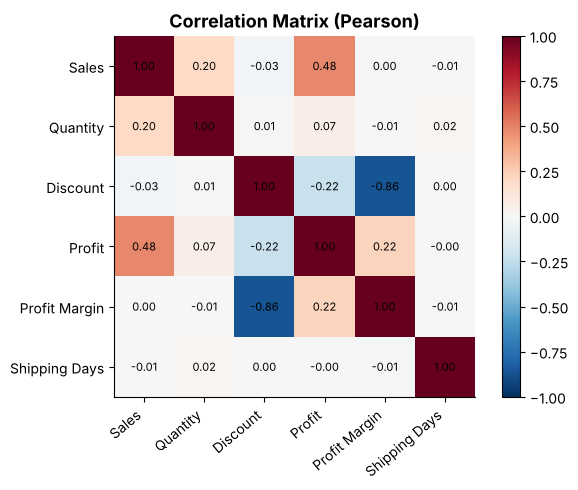

In [34]:
corr = df[['Sales','Quantity','Discount','Profit','Profit Margin','Shipping Days']].corr()
spear = df[['Sales','Quantity','Discount','Profit','Profit Margin','Shipping Days']].corr(method='spearman')
display(corr.round(3)); print('Spearman (rank) correlation of Discount with Profit: %.3f' % spear.loc['Discount','Profit'])
fig, ax = plt.subplots(figsize=(6.5, 5)); im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=40, ha='right'); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, fraction=.046); ax.set_title('Correlation Matrix (Pearson)'); save('10_correlation'); plt.show()

**Meaning:** Pearson correlation measures *linear* association from −1 to +1. Discount vs Profit = −0.22 (weak-to-moderate negative), Discount vs Profit Margin = −0.86 (strong negative). The relationship is much stronger for margin than for absolute profit because absolute profit is dominated by order size (Sales vs Profit = +0.48). **Correlation ≠ causation.**

In [35]:
# Hypothesis tests: are profit margins different across groups?
# 1) Welch t-test: discounted vs non-discounted lines
a = df.loc[df.Discount == 0, 'Profit']; b = df.loc[df.Discount > 0, 'Profit']
t, p = stats.ttest_ind(a, b, equal_var=False); print(f'Mean profit per line — no discount ${a.mean():.2f} vs discounted ${b.mean():.2f} | Welch t={t:.2f}, p={p:.2e}')
# 2) Kruskal-Wallis (non-parametric, suits skewed data): profit margin across the 3 categories and 4 regions
for col in ['Category', 'Region', 'Segment']:
    groups = [g['Profit Margin'].values for _, g in df.groupby(col)]; h, p = stats.kruskal(*groups)
    print(f'Kruskal-Wallis on profit margin by {col:9s}: H={h:8.2f}, p={p:.2e}')
# 3) Discount vs profit within the Central region only (does the pattern hold inside a single region?)
for r, g in df.groupby('Region'): print(f'{r:8s} corr(Discount, Profit margin) = {g[["Discount","Profit Margin"]].corr().iloc[0,1]:.3f}')

Mean profit per line — no discount $66.90 vs discounted $-6.66 | Welch t=15.74, p=4.36e-55
Kruskal-Wallis on profit margin by Category : H=  996.63, p=3.84e-217
Kruskal-Wallis on profit margin by Region   : H=  236.98, p=4.29e-51
Kruskal-Wallis on profit margin by Segment  : H=    9.60, p=8.24e-03
Central  corr(Discount, Profit margin) = -0.919
East     corr(Discount, Profit margin) = -0.868
South    corr(Discount, Profit margin) = -0.880
West     corr(Discount, Profit margin) = -0.761


**Reading the tests:** Very small p-values mean the observed differences are unlikely to be due to chance alone. They show the differences are real in this sample, **not why** they occur. Because profit is highly skewed we favour the rank-based Kruskal–Wallis test. The discount–margin correlation is strongly negative in every region (−0.76 to −0.92), so the pattern is not driven by a single region. The Segment difference is statistically significant (p = 0.008) but small in size (margins of 11.5–14.0 %).

In [36]:
# Is Central's weakness explained by its discount mix? Compare margins on like-for-like discount bands
mix = df.pivot_table(index='Region', columns='Discount Band', values='Sales', aggfunc='sum')
mix = mix.div(mix.sum(axis=1), axis=0)[['No discount','1-10%','11-20%','21-30%','31-50%','>50%']]*100
print('Share of each region\'s sales by discount band (%)'); display(mix.round(1))
mg = df.pivot_table(index='Region', columns='Discount Band', values='Profit', aggfunc='sum')/df.pivot_table(index='Region', columns='Discount Band', values='Sales', aggfunc='sum')*100
print('Profit margin by region and discount band (%)'); display(mg[['No discount','11-20%','21-30%','31-50%','>50%']].round(1))

Share of each region's sales by discount band (%)


Discount Band,No discount,1-10%,11-20%,21-30%,31-50%,>50%
Region,,,,,,
Central,48.50,1.50,24.20,13.00,8.10,4.70
East,50.30,6.90,21.30,5.60,13.00,2.80
South,55.10,NaN,26.80,NaN,15.10,2.90
West,39.60,NaN,58.10,NaN,1.00,1.40


Profit margin by region and discount band (%)


Discount Band,No discount,11-20%,21-30%,31-50%,>50%
Region,,,,,
Central,31.30,11.60,-10.10,-23.10,-154.50
East,30.80,14.60,-10.00,-20.70,-103.50
South,29.20,8.20,NaN,-27.80,-73.70
West,26.70,11.40,NaN,-60.40,-118.00


**Reading:** Central earns 25.8 % of its sales on lines discounted above 20 % (East 21.4 %, South 18.0 %, West only 2.4 %). Within the no-discount band, regional margins are similar (27–31 %), and within 11–20 % they range from 8 % to 15 %. So regional margin gaps are **partly a discount-mix effect**: West's high margin goes with very little deep discounting, and Central's weak margin goes with a heavy deep-discount share. This is association only — product mix and customer mix may also contribute and cannot be separated with this data. (East also discounts deeply yet keeps a 13.5 % margin, so discount mix is not the whole story.)

## F. Forecasting (optional — included because 48 months of data are available)
**Question:** can monthly sales be forecast better than a naive rule? **Design:** train on 2014–2016 (36 months), test on 2017 (12 months) — a chronological split, never random. **Baselines:** (1) *seasonal naive* = same month last year; (2) *naive* = last observed value. **Model:** linear regression on a time trend plus month-of-year dummies (captures growth + seasonality). **Metrics:** MAE, RMSE, MAPE.

In [37]:
from sklearn.linear_model import LinearRegression
ms = df.groupby(df['Order Date'].dt.to_period('M')).Sales.sum(); ms.index = ms.index.to_timestamp()
X = pd.DataFrame({'t': np.arange(len(ms))}, index=ms.index)
X = X.join(pd.get_dummies(ms.index.month, prefix='m', drop_first=True).set_index(ms.index).astype(int))
train, test = ms.index < '2017-01-01', ms.index >= '2017-01-01'
model = LinearRegression().fit(X[train], ms[train]); pred = pd.Series(model.predict(X[test]), index=ms.index[test])
snaive = pd.Series(ms[train].values[-12:], index=ms.index[test]); naive = pd.Series(ms[train].values[-1], index=ms.index[test])
def metrics(y, yhat): return pd.Series({'MAE': np.mean(abs(y-yhat)), 'RMSE': np.sqrt(np.mean((y-yhat)**2)), 'MAPE %': np.mean(abs((y-yhat)/y))*100})
res = pd.DataFrame({'Trend + month dummies (LinearRegression)': metrics(ms[test], pred), 'Seasonal naive (same month last year)': metrics(ms[test], snaive), 'Naive (last value)': metrics(ms[test], naive)}).T
res

,MAE,RMSE,MAPE %
Trend + month dummies (LinearRegression),"10,793.89","14,557.85",17.25
Seasonal naive (same month last year),"15,467.89","18,985.70",24.52
Naive (last value),"39,472.57","44,191.89",97.32


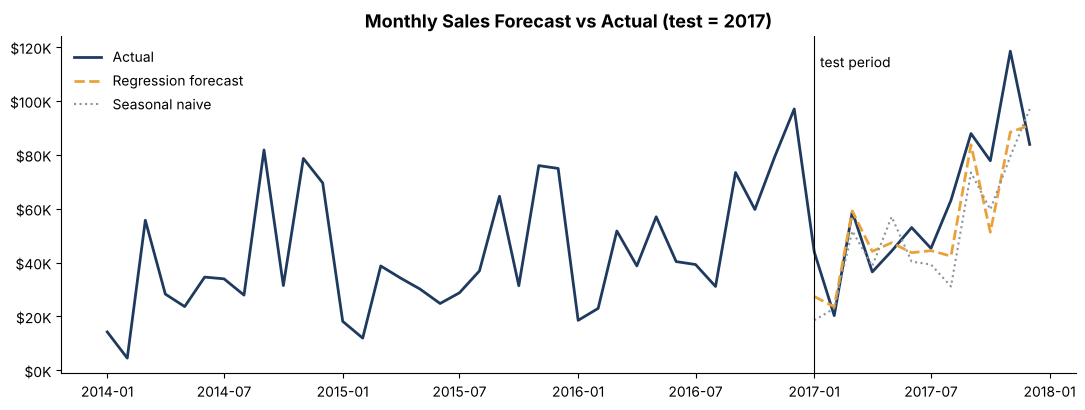

Lowest MAPE: Trend + month dummies (LinearRegression) | 17.3%


In [38]:
fig, ax = plt.subplots(figsize=(11, 4.2)); ax.plot(ms.index, ms, color=NAVY, lw=2, label='Actual')
ax.plot(pred.index, pred, color=GOLD, lw=2, ls='--', label='Regression forecast'); ax.plot(snaive.index, snaive, color=GREY, lw=1.5, ls=':', label='Seasonal naive')
ax.axvline(pd.Timestamp('2016-12-31'), color='k', lw=.8); ax.text(pd.Timestamp('2017-01-10'), ms.max()*.95, 'test period')
ax.yaxis.set_major_formatter(money); ax.set_title('Monthly Sales Forecast vs Actual (test = 2017)'); ax.legend(frameon=False); save('11_forecast'); plt.show()
best = res['MAPE %'].idxmin(); print('Lowest MAPE:', best, '| %.1f%%' % res['MAPE %'].min())

**Interpretation and limits:** Only the model's performance on the 12 held-out months is reported (no in-sample claims). On the 2017 test the trend + seasonality regression had a MAPE of about 17 %, versus about 25 % for the seasonal-naive rule and about 97 % for the naive rule, so it beat both baselines: it captures the seasonal shape *and* the growth that the seasonal-naive rule misses. Still, a ~17 % average monthly error is sizeable, 36 training points and 12 test points are few, and a linear trend may not continue. The forecast supports planning discussions (e.g. building inventory ahead of September–December), not precise targets.

## G. Summary of validated findings
(All numbers below are computed from the data above and re-checked in SQL; see `sql/business_queries.sql`.)

In [39]:
print(f'Sales ${total_sales:,.2f} | Profit ${total_profit:,.2f} | Margin {total_profit/total_sales*100:.2f}% | Orders {n_orders:,} | Customers {n_cust}')
print('Furniture margin %.1f%% vs Technology %.1f%% / Office Supplies %.1f%%' % tuple(kpi('Category').loc[['Furniture','Technology','Office Supplies'],'Margin %']))
print('Loss-making sub-categories:', ', '.join(sub[sub.Profit<0].index))
print('Loss-making products (by ID): %d | Loss-making states: %d | Central margin %.1f%% vs West %.1f%%' % (neg.sum(), (state.Profit<0).sum(), reg.loc['Central','Margin %'], reg.loc['West','Margin %']))
print('Discount >20%%: %d lines, profit $%s' % (len(high_disc), f'{high_disc.Profit.sum():,.0f}'))

Sales $2,297,200.86 | Profit $286,397.02 | Margin 12.47% | Orders 5,009 | Customers 793
Furniture margin 2.5% vs Technology 17.4% / Office Supplies 17.0%
Loss-making sub-categories: Tables, Bookcases, Supplies
Loss-making products (by ID): 299 | Loss-making states: 10 | Central margin 7.9% vs West 14.9%
Discount >20%: 1393 lines, profit $-135,376


## H. Export
The cleaned dataset (all 9,994 rows, 33 columns) is the single source for SQL and Power BI.

In [40]:
df.to_csv('../data/processed/cleaned_sales.csv', index=False)
chk = pd.read_csv('../data/processed/cleaned_sales.csv'); print('Exported:', chk.shape, '| Sales check:', round(chk.Sales.sum(), 2))

Exported: (9994, 33) | Sales check: 2297200.86
